# Data Quality and Exploratory Analysis: Customer Churn

**Track:** Data Analytics | **Author:** Govarthan

**Objective:** Audit and clean a customer churn dataset, document every data-quality decision, and look at the first patterns that explain why customers leave.

**Dataset:** `customer_churn_sample.csv` (synthetic customer records supplied with the task).

**Steps in this notebook**
1. Load and profile the data (columns, types, missing values, duplicates, outliers)
2. Clean the data and record the assumptions
3. Validate the cleaned data with checks
4. Summary statistics and distributions
5. First patterns related to churn
6. Export the clean dataset and a data dictionary

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)
pd.set_option("display.width", 140)

raw = pd.read_csv("customer_churn_sample.csv")
print("Rows, columns:", raw.shape)
raw

Rows, columns: (15, 11)


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes
5,CUST-1006,Male,31,18,Basic,49.99,899.82,One Year,2,UPI,No
6,CUST-1007,Female,23,3,Basic,49.99,149.97,Month-to-Month,6,Credit Card,Yes
7,CUST-1008,Male,60,48,Enterprise,149.99,7199.52,Two Year,1,Bank Transfer,No
8,CUST-1009,Female,38,15,Pro,79.99,1199.85,One Year,2,Credit Card,No
9,CUST-1010,Male,27,4,Basic,49.99,199.96,Month-to-Month,4,UPI,Yes


## 1. Profile the data

In [2]:
# Column names, data types and non-null counts
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     str    
 1   Gender            15 non-null     str    
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     str    
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     str    
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     str    
 10  Churn             15 non-null     str    
dtypes: float64(2), int64(3), str(6)
memory usage: 1.4 KB


In [3]:
# Missing values per column
missing = raw.isnull().sum()
print(missing)
print("Total missing values:", missing.sum())

CustomerID          0
Gender              0
Age                 0
TenureMonths        0
SubscriptionType    0
MonthlyCharges      0
TotalCharges        0
ContractType        0
SupportTickets      0
PaymentMethod       0
Churn               0
dtype: int64
Total missing values: 0


In [4]:
# Duplicates: fully identical rows and repeated customer IDs
print("Duplicate rows       :", raw.duplicated().sum())
print("Duplicate CustomerID :", raw["CustomerID"].duplicated().sum())

Duplicate rows       : 0
Duplicate CustomerID : 0


In [5]:
# Categorical columns: list every distinct value (to spot typos, spaces or mixed case)
for col in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    print(col, "->", sorted(raw[col].unique()))
    print("   has leading/trailing spaces:", (raw[col] != raw[col].str.strip()).any())

Gender -> ['Female', 'Male']
   has leading/trailing spaces: False
SubscriptionType -> ['Basic', 'Enterprise', 'Pro']
   has leading/trailing spaces: False
ContractType -> ['Month-to-Month', 'One Year', 'Two Year']
   has leading/trailing spaces: False
PaymentMethod -> ['Bank Transfer', 'Credit Card', 'Debit Card', 'UPI']
   has leading/trailing spaces: False
Churn -> ['No', 'Yes']
   has leading/trailing spaces: False


In [6]:
# Outliers using the IQR rule (value below Q1 - 1.5*IQR or above Q3 + 1.5*IQR)
num_cols = ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]
rows = []
for col in num_cols:
    q1, q3 = raw[col].quantile(0.25), raw[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((raw[col] < low) | (raw[col] > high)).sum()
    rows.append([col, raw[col].min(), raw[col].max(), round(low, 2), round(high, 2), n_out])
pd.DataFrame(rows, columns=["column", "min", "max", "lower_fence", "upper_fence", "outliers"])

,column,min,max,lower_fence,upper_fence,outliers
0,Age,23.00,60.00,4.50,72.50,0
1,TenureMonths,2.00,48.00,-23.00,57.00,0
2,MonthlyCharges,49.99,149.99,-47.51,212.49,0
3,TotalCharges,99.98,7199.52,-3689.82,7349.46,0
4,SupportTickets,0.00,6.00,-3.50,8.50,0


## 2. Clean the data (with assumptions)

The profile above shows no missing values, no duplicates and no outliers, so no rows need to be removed or filled. I still apply a few safe standardisation steps so the cleaning is repeatable if the data is refreshed.

| Step | Assumption / reason |
|---|---|
| Trim spaces and fix text case in text columns | Prevents "UPI " and "upi" being counted as different values |
| Keep `CustomerID` as text | It is an identifier, not a number |
| Add `ChurnFlag` (Yes = 1, No = 0) | Makes churn rates easy to calculate; the original `Churn` column is kept |
| Add `AvgChargePerMonth` = TotalCharges / TenureMonths | Used to cross-check billing |
| Do not drop or change any values | Nothing was found that needs fixing |

In [7]:
clean = raw.copy()

# 1) Standardise text columns
text_cols = ["CustomerID", "Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]
for col in text_cols:
    clean[col] = clean[col].astype(str).str.strip()
for col in ["Gender", "SubscriptionType", "Churn"]:
    clean[col] = clean[col].str.title()   # PaymentMethod is left as is so "UPI" stays in capitals
clean["CustomerID"] = clean["CustomerID"].str.upper()

# 2) Correct data types
clean["Age"] = clean["Age"].astype(int)
clean["TenureMonths"] = clean["TenureMonths"].astype(int)
clean["SupportTickets"] = clean["SupportTickets"].astype(int)
clean["MonthlyCharges"] = clean["MonthlyCharges"].astype(float)
clean["TotalCharges"] = clean["TotalCharges"].astype(float)

# 3) Helper columns
clean["ChurnFlag"] = (clean["Churn"] == "Yes").astype(int)
clean["AvgChargePerMonth"] = (clean["TotalCharges"] / clean["TenureMonths"]).round(2)

print("Rows before:", len(raw), "| Rows after:", len(clean))
clean.dtypes

Rows before: 15 | Rows after: 15


CustomerID               str
Gender                   str
Age                    int64
TenureMonths           int64
SubscriptionType         str
MonthlyCharges       float64
TotalCharges         float64
ContractType             str
SupportTickets         int64
PaymentMethod            str
Churn                    str
ChurnFlag              int64
AvgChargePerMonth    float64
dtype: object

## 3. Validation checks

In [8]:
checks = {}
checks["No missing values"] = clean.isnull().sum().sum() == 0
checks["CustomerID is unique"] = clean["CustomerID"].is_unique
checks["Age between 18 and 100"] = clean["Age"].between(18, 100).all()
checks["TenureMonths is 0 or more"] = (clean["TenureMonths"] >= 0).all()
checks["MonthlyCharges is above 0"] = (clean["MonthlyCharges"] > 0).all()
checks["SupportTickets is 0 or more"] = (clean["SupportTickets"] >= 0).all()
checks["Churn is only Yes/No"] = clean["Churn"].isin(["Yes", "No"]).all()
checks["Gender is only Male/Female"] = clean["Gender"].isin(["Male", "Female"]).all()
checks["PaymentMethod has expected values"] = clean["PaymentMethod"].isin(["Credit Card", "Debit Card", "UPI", "Bank Transfer"]).all()
checks["ContractType has expected values"] = clean["ContractType"].isin(["Month-to-Month", "One Year", "Two Year"]).all()

# TotalCharges should equal TenureMonths x MonthlyCharges (allow 1 cent rounding)
diff = (clean["TotalCharges"] - clean["TenureMonths"] * clean["MonthlyCharges"]).abs()
checks["TotalCharges = Tenure x MonthlyCharges"] = (diff <= 0.01).all()

# Each subscription plan should have one price
checks["One monthly price per plan"] = (clean.groupby("SubscriptionType")["MonthlyCharges"].nunique() == 1).all()

result = pd.DataFrame({"check": list(checks.keys()), "passed": list(checks.values())})
print(result.to_string(index=False))
assert result["passed"].all(), "A validation check failed"
print("\nAll", len(result), "checks passed")

                                 check  passed
                     No missing values    True
                  CustomerID is unique    True
                Age between 18 and 100    True
             TenureMonths is 0 or more    True
             MonthlyCharges is above 0    True
           SupportTickets is 0 or more    True
                  Churn is only Yes/No    True
            Gender is only Male/Female    True
     PaymentMethod has expected values    True
      ContractType has expected values    True
TotalCharges = Tenure x MonthlyCharges    True
            One monthly price per plan    True

All 12 checks passed


In [9]:
# Plan prices (used in the check above)
clean.groupby("SubscriptionType")["MonthlyCharges"].agg(["min", "max", "count"])

,min,max,count
SubscriptionType,,,
Basic,49.99,49.99,7
Enterprise,149.99,149.99,4
Pro,79.99,79.99,4


## 4. Summary statistics and distributions

In [10]:
clean[["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]].describe().round(2)

,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.00,15.00,15.00,15.00,15.00
mean,39.07,18.80,84.66,2088.48,2.53
std,11.39,14.33,42.74,2407.37,1.92
min,23.00,2.00,49.99,99.98,0.00
25%,30.00,7.00,49.99,449.91,1.00
50%,38.00,15.00,79.99,1099.78,2.00
75%,47.00,27.00,114.99,3209.73,4.00
max,60.00,48.00,149.99,7199.52,6.00


In [11]:
# Share of customers in each category
for col in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    print(clean[col].value_counts().to_frame("customers").assign(percent=lambda d: (d["customers"] / len(clean) * 100).round(1)))
    print()

        customers  percent
Gender                    
Female          8     53.3
Male            7     46.7

                  customers  percent
SubscriptionType                    
Basic                     7     46.7
Pro                       4     26.7
Enterprise                4     26.7

                customers  percent
ContractType                      
Month-to-Month          7     46.7
One Year                4     26.7
Two Year                4     26.7

               customers  percent
PaymentMethod                    
Credit Card            6     40.0
UPI                    4     26.7
Bank Transfer          3     20.0
Debit Card             2     13.3

       customers  percent
Churn                    
No             8     53.3
Yes            7     46.7



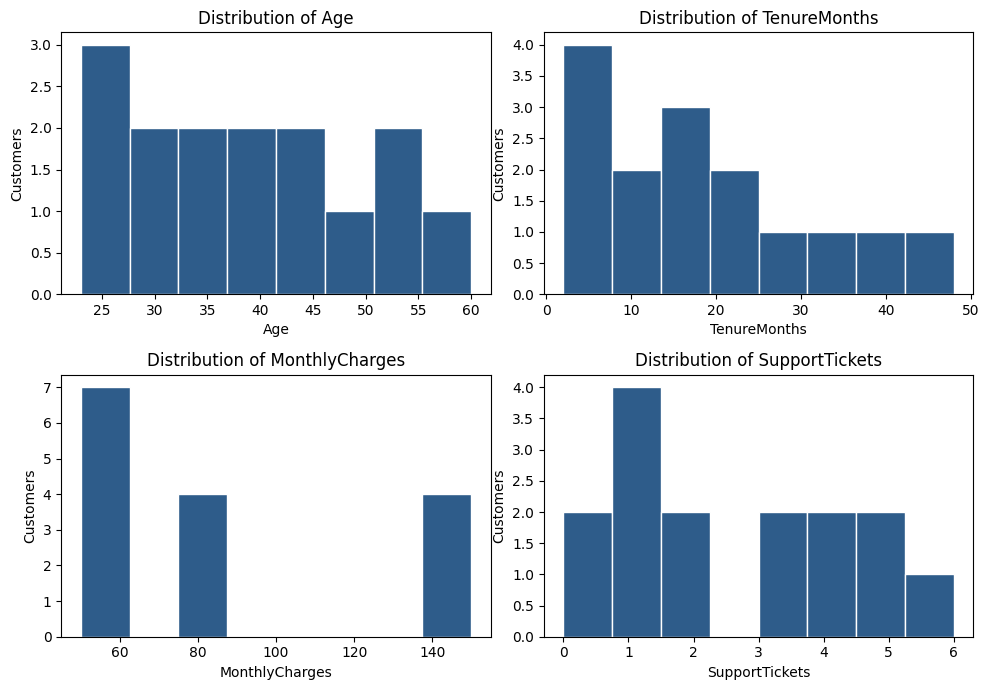

In [12]:
# Distributions of the numeric columns
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), ["Age", "TenureMonths", "MonthlyCharges", "SupportTickets"]):
    ax.hist(clean[col], bins=8, color="#2E5C8A", edgecolor="white")
    ax.set_title("Distribution of " + col)
    ax.set_xlabel(col); ax.set_ylabel("Customers")
plt.tight_layout()
plt.savefig("images/distributions.png", dpi=150)
plt.show()

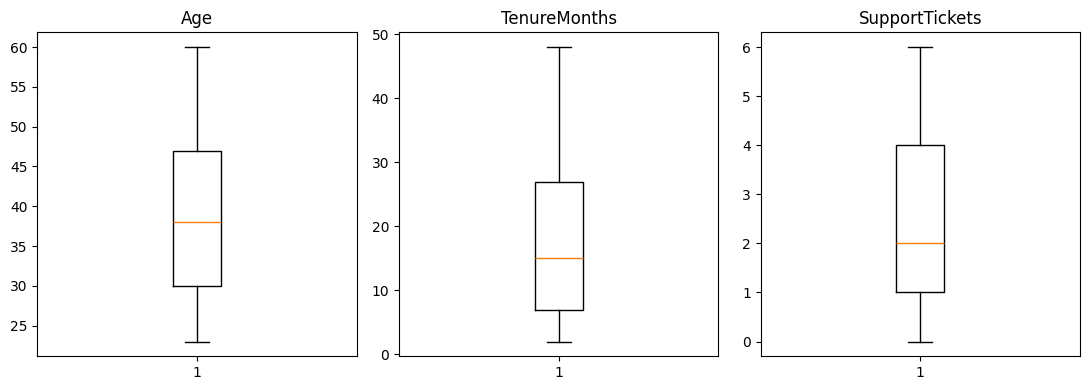

In [13]:
# Box plots to see the spread and any extreme values
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, col in zip(axes, ["Age", "TenureMonths", "SupportTickets"]):
    ax.boxplot(clean[col], vert=True)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("images/boxplots.png", dpi=150)
plt.show()

## 5. First patterns: what is linked to churn?

In [14]:
overall = clean["ChurnFlag"].mean() * 100
print("Overall churn rate: {:.1f}% ({} of {} customers)".format(overall, clean["ChurnFlag"].sum(), len(clean)))

for col in ["ContractType", "SubscriptionType", "PaymentMethod", "Gender"]:
    t = clean.groupby(col)["ChurnFlag"].agg(customers="count", churned="sum")
    t["churn_rate_%"] = (t["churned"] / t["customers"] * 100).round(1)
    print(t, "\n")

Overall churn rate: 46.7% (7 of 15 customers)
                customers  churned  churn_rate_%
ContractType                                    
Month-to-Month          7        7         100.0
One Year                4        0           0.0
Two Year                4        0           0.0 

                  customers  churned  churn_rate_%
SubscriptionType                                  
Basic                     7        5          71.4
Enterprise                4        0           0.0
Pro                       4        2          50.0 

               customers  churned  churn_rate_%
PaymentMethod                                  
Bank Transfer          3        0           0.0
Credit Card            6        2          33.3
Debit Card             2        2         100.0
UPI                    4        3          75.0 

        customers  churned  churn_rate_%
Gender                                  
Female          8        4          50.0
Male            7        3          4

In [15]:
# Average tenure, tickets, age and price: churned vs stayed
clean.groupby("Churn")[["TenureMonths", "SupportTickets", "Age", "MonthlyCharges"]].mean().round(2)

,TenureMonths,SupportTickets,Age,MonthlyCharges
Churn,,,,
No,29.12,1.00,46.62,107.49
Yes,7.00,4.29,30.43,58.56


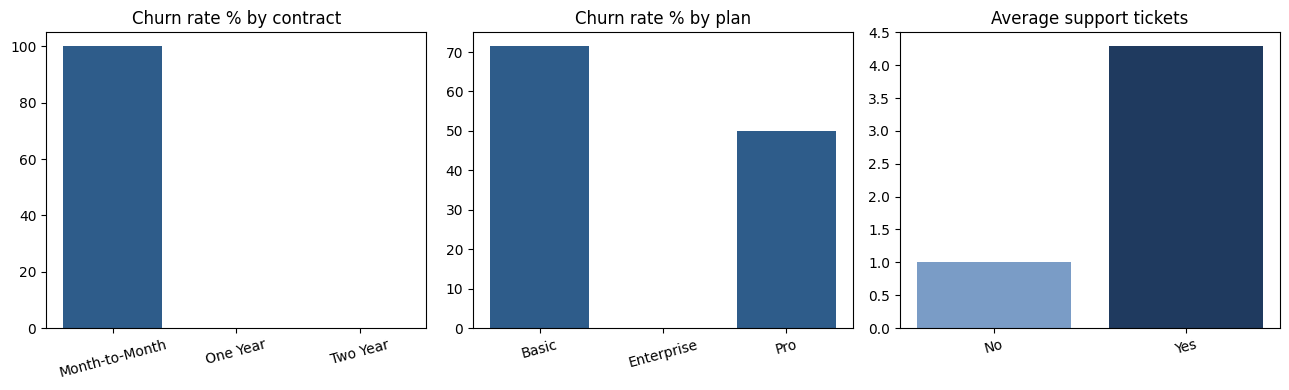

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
rate_contract = clean.groupby("ContractType")["ChurnFlag"].mean() * 100
rate_plan = clean.groupby("SubscriptionType")["ChurnFlag"].mean() * 100
axes[0].bar(rate_contract.index, rate_contract.values, color="#2E5C8A"); axes[0].set_title("Churn rate % by contract")
axes[1].bar(rate_plan.index, rate_plan.values, color="#2E5C8A"); axes[1].set_title("Churn rate % by plan")
means = clean.groupby("Churn")["SupportTickets"].mean()
axes[2].bar(means.index, means.values, color=["#7A9CC6", "#1F3A5F"]); axes[2].set_title("Average support tickets")
for ax in axes: ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("images/churn_patterns.png", dpi=150)
plt.show()

In [17]:
# Support tickets vs churn
print(clean.groupby("SupportTickets")["ChurnFlag"].agg(customers="count", churned="sum"))

                customers  churned
SupportTickets                    
0                       2        0
1                       4        0
2                       2        0
3                       2        2
4                       2        2
5                       2        2
6                       1        1


## 6. Export the clean data and data dictionary

In [18]:
clean.to_csv("customer_churn_clean.csv", index=False)

dictionary = pd.DataFrame([
    ["CustomerID", "text", "Unique customer identifier", "CUST-1001 to CUST-1015"],
    ["Gender", "text", "Customer gender", "Male, Female"],
    ["Age", "integer", "Customer age in years", "23 to 60"],
    ["TenureMonths", "integer", "Months the customer has been subscribed", "2 to 48"],
    ["SubscriptionType", "text", "Subscription plan", "Basic, Pro, Enterprise"],
    ["MonthlyCharges", "decimal", "Monthly fee for the plan", "49.99, 79.99, 149.99"],
    ["TotalCharges", "decimal", "Total billed so far (about TenureMonths x MonthlyCharges)", "99.98 to 7199.52"],
    ["ContractType", "text", "Contract length", "Month-to-Month, One Year, Two Year"],
    ["SupportTickets", "integer", "Number of support tickets raised", "0 to 6"],
    ["PaymentMethod", "text", "How the customer pays", "Credit Card, Debit Card, UPI, Bank Transfer"],
    ["Churn", "text", "Did the customer leave? (original column)", "Yes, No"],
    ["ChurnFlag", "integer", "Added: 1 if Churn = Yes, else 0", "0, 1"],
    ["AvgChargePerMonth", "decimal", "Added: TotalCharges / TenureMonths (billing cross-check)", "equals MonthlyCharges"],
], columns=["column", "type", "description", "values / range"])
dictionary.to_csv("data_dictionary.csv", index=False)
dictionary

,column,type,description,values / range
0,CustomerID,text,Unique customer identifier,CUST-1001 to CUST-1015
1,Gender,text,Customer gender,"Male, Female"
2,Age,integer,Customer age in years,23 to 60
3,TenureMonths,integer,Months the customer has been subscribed,2 to 48
4,SubscriptionType,text,Subscription plan,"Basic, Pro, Enterprise"
5,MonthlyCharges,decimal,Monthly fee for the plan,"49.99, 79.99, 149.99"
6,TotalCharges,decimal,Total billed so far (about TenureMonths x Mont...,99.98 to 7199.52
7,ContractType,text,Contract length,"Month-to-Month, One Year, Two Year"
8,SupportTickets,integer,Number of support tickets raised,0 to 6
9,PaymentMethod,text,How the customer pays,"Credit Card, Debit Card, UPI, Bank Transfer"


In [19]:
# Confirm the exported file loads correctly
check = pd.read_csv("customer_churn_clean.csv")
print(check.shape)
check.head()

(15, 13)


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn,ChurnFlag,AvgChargePerMonth
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes,1,49.99
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No,0,79.99
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes,1,49.99
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No,0,149.99
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes,1,79.99


## 7. Limitations

- The dataset has only 15 customers, so the patterns above are only a first look and are not statistically reliable.
- The data is synthetic (made for practice), so real-world conclusions should not be drawn from it.
- Seeing a link between two columns, such as churn and contract type, does not prove one causes the other.